In [1]:
!pip install umap-learn -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

import umap

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
data = load_breast_cancer()
X = data.data          # (569, 30)
y = data.target        # 0 = malignant, 1 = benign

print("Форма X:", X.shape)
print("Классы:", data.target_names)
print("Распределение классов:", np.bincount(y))
print("Признаки (первые 5):", data.feature_names[:5])

df = pd.DataFrame(X, columns=data.feature_names)
df["target"] = y
df.head()

Форма X: (569, 30)
Классы: ['malignant' 'benign']
Распределение классов: [212 357]
Признаки (первые 5): ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)

rf_base = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

t0 = time.time()
rf_base.fit(X_train, y_train)
train_time_base = time.time() - t0

t0 = time.time()
y_pred_base = rf_base.predict(X_test)
predict_time_base = time.time() - t0

acc_base = accuracy_score(y_test, y_pred_base)

print(f"Accuracy на 30 исходных признаках: {acc_base:.4f}")
print(f"Время обучения: {train_time_base:.3f} с")
print(f"Время предсказания: {predict_time_base:.3f} с")
print("\nClassification report:")
print(classification_report(y_test, y_pred_base, target_names=data.target_names))

Train: (455, 30)  Test: (114, 30)
Accuracy на 30 исходных признаках: 0.9474
Время обучения: 1.240 с
Время предсказания: 0.102 с

Classification report:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



Исходное число признаков: 30
Число компонент после PCA (95% дисперсии): 10
Сохранённая суммарная дисперсия: 0.9527


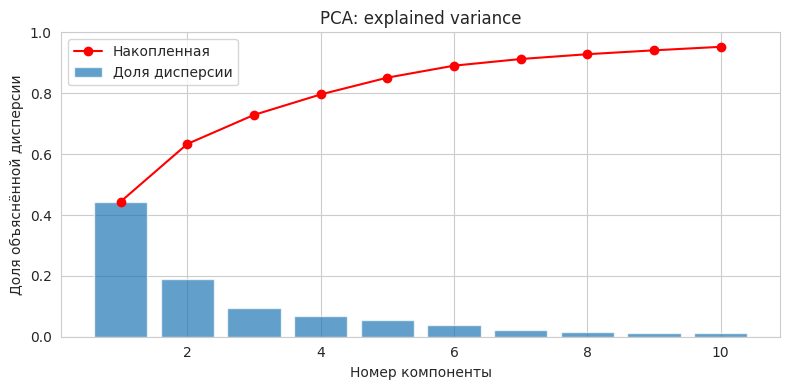

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print(f"Исходное число признаков: {X_train.shape[1]}")
print(f"Число компонент после PCA (95% дисперсии): {X_train_pca.shape[1]}")
print(f"Сохранённая суммарная дисперсия: {pca.explained_variance_ratio_.sum():.4f}")

# Посмотрим вклад первых компонент
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1),
        pca.explained_variance_ratio_, alpha=0.7, label="Доля дисперсии")
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         np.cumsum(pca.explained_variance_ratio_), "o-", color="red", label="Накопленная")
plt.xlabel("Номер компоненты")
plt.ylabel("Доля объяснённой дисперсии")
plt.title("PCA: explained variance")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
rf_pca = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

t0 = time.time()
rf_pca.fit(X_train_pca, y_train)
train_time_pca = time.time() - t0

t0 = time.time()
y_pred_pca = rf_pca.predict(X_test_pca)
predict_time_pca = time.time() - t0

acc_pca = accuracy_score(y_test, y_pred_pca)

print(f"Accuracy на PCA-признаках ({X_train_pca.shape[1]} комп.): {acc_pca:.4f}")
print(f"Время обучения: {train_time_pca:.3f} с")
print(f"Время предсказания: {predict_time_pca:.3f} с")
print("\nClassification report:")
print(classification_report(y_test, y_pred_pca, target_names=data.target_names))

Accuracy на PCA-признаках (10 комп.): 0.9474
Время обучения: 1.420 с
Время предсказания: 0.081 с

Classification report:
              precision    recall  f1-score   support

   malignant       0.95      0.90      0.93        42
      benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



In [6]:
delta_acc = acc_base - acc_pca
speedup_train = train_time_base / train_time_pca if train_time_pca > 0 else float("inf")
speedup_pred  = predict_time_base / predict_time_pca if predict_time_pca > 0 else float("inf")

print("=" * 55)
print(f"{'Метрика':<30}{'30 признаков':>12}{'PCA':>12}")
print("-" * 55)
print(f"{'Accuracy':<30}{acc_base:>12.4f}{acc_pca:>12.4f}")
print(f"{'Число признаков':<30}{X_train.shape[1]:>12}{X_train_pca.shape[1]:>12}")
print(f"{'Время обучения, с':<30}{train_time_base:>12.3f}{train_time_pca:>12.3f}")
print(f"{'Время предсказания, с':<30}{predict_time_base:>12.3f}{predict_time_pca:>12.3f}")
print("=" * 55)
print(f"Δ accuracy (base − PCA): {delta_acc:+.4f}  ({delta_acc*100:+.2f} п.п.)")
print(f"Ускорение обучения: {speedup_train:.2f}×")
print(f"Ускорение предсказания: {speedup_pred:.2f}×")

if delta_acc > 0:
    print("\nВывод: качество немного УПАЛО после PCA.")
elif delta_acc < 0:
    print("\nВывод: качество даже немного ВЫРОСЛО после PCA (PCA выступил как регуляризация).")
else:
    print("\nВывод: качество не изменилось.")

Метрика                       30 признаков         PCA
-------------------------------------------------------
Accuracy                            0.9474      0.9474
Число признаков                         30          10
Время обучения, с                    1.240       1.420
Время предсказания, с                0.102       0.081
Δ accuracy (base − PCA): +0.0000  (+0.00 п.п.)
Ускорение обучения: 0.87×
Ускорение предсказания: 1.25×

Вывод: качество не изменилось.


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


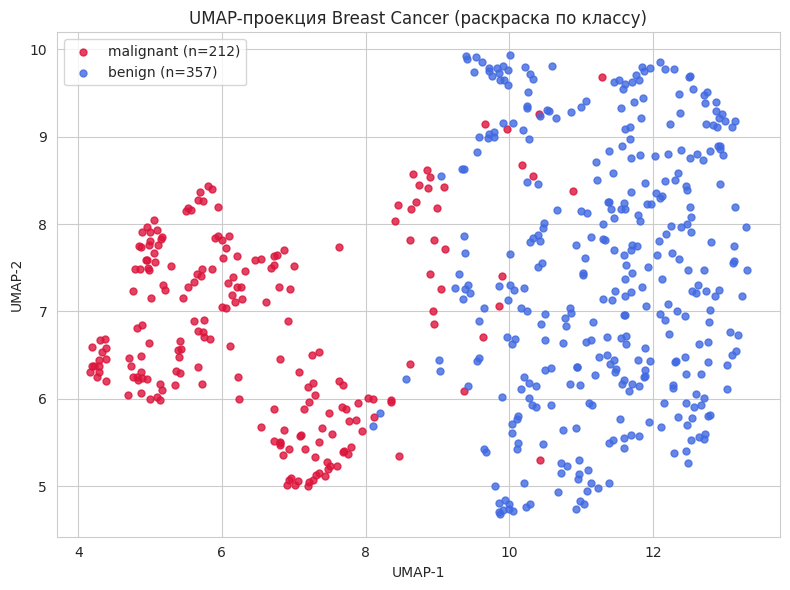

In [7]:
# UMAP строим на масштабированных данных (все 30 признаков)
umap_reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE)
X_umap = umap_reducer.fit_transform(scaler.transform(X))  # 569 × 2

plt.figure(figsize=(8, 6))
for cls, name, color in [(0, "malignant", "crimson"), (1, "benign", "royalblue")]:
    mask = y == cls
    plt.scatter(X_umap[mask, 0], X_umap[mask, 1],
                s=25, alpha=0.8, label=f"{name} (n={mask.sum()})", c=color)
plt.title("UMAP-проекция Breast Cancer (раскраска по классу)")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.legend()
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


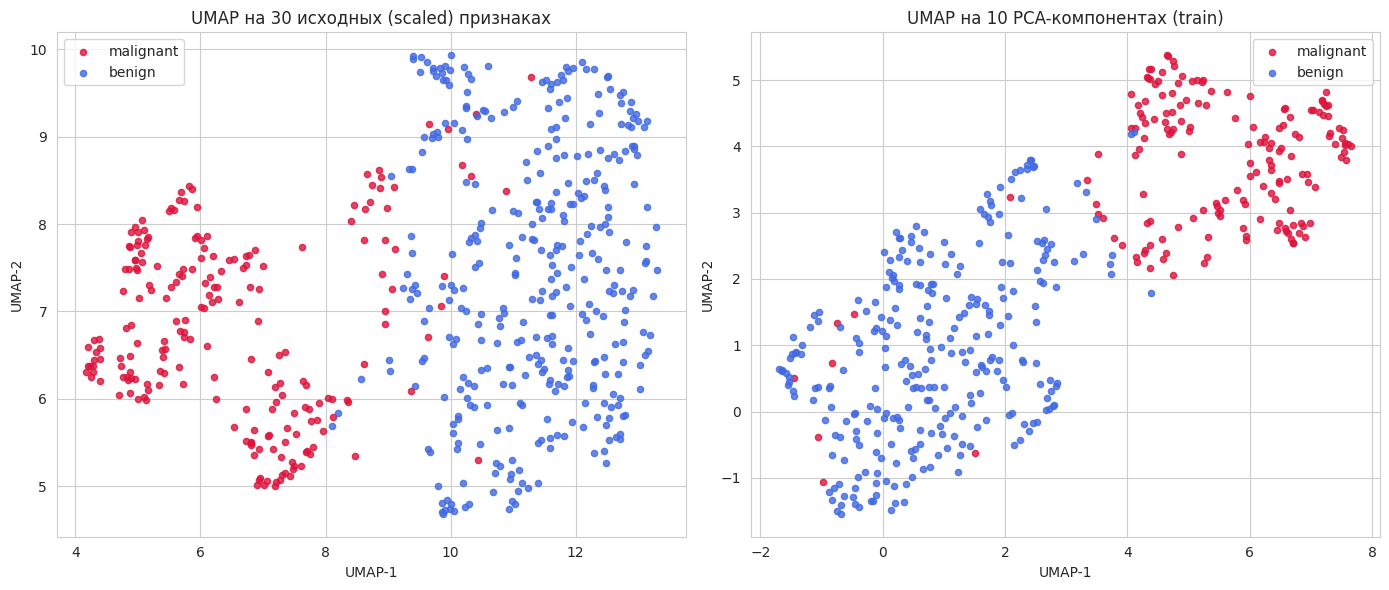

In [8]:
# UMAP на PCA-признаках + сравним еще визуально
umap_on_pca = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE)
X_umap_pca = umap_on_pca.fit_transform(X_train_pca)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for cls, name, color in [(0, "malignant", "crimson"), (1, "benign", "royalblue")]:
    mask = y == cls
    axes[0].scatter(X_umap[mask, 0], X_umap[mask, 1], s=20, alpha=0.8, c=color, label=name)

for cls, name, color in [(0, "malignant", "crimson"), (1, "benign", "royalblue")]:
    mask = y_train == cls
    axes[1].scatter(X_umap_pca[mask, 0], X_umap_pca[mask, 1], s=20, alpha=0.8, c=color, label=name)

axes[0].set_title("UMAP на 30 исходных (scaled) признаках")
axes[1].set_title(f"UMAP на {X_train_pca.shape[1]} PCA-компонентах (train)")
for ax in axes:
    ax.set_xlabel("UMAP-1"); ax.set_ylabel("UMAP-2"); ax.legend()
plt.tight_layout()
plt.show()

In [9]:
print("ИТОГОВЫЙ ВЫВОД")
print("-" * 60)
print(f"1) Базовая модель (30 признаков): accuracy = {acc_base:.4f}")
print(f"2) PCA(0.95) сохранил {X_train_pca.shape[1]} компонент "
      f"({pca.explained_variance_ratio_.sum()*100:.1f}% дисперсии).")
print(f"3) Модель на PCA: accuracy = {acc_pca:.4f}")
print(f"   Изменение: {delta_acc*100:+.2f} п.п.")
print(f"4) Ускорение обучения: {speedup_train:.2f}×, предсказания: {speedup_pred:.2f}×")
print()
print("Баланс: PCA уменьшил размерность в "
      f"{X_train.shape[1] / X_train_pca.shape[1]:.1f}×, "
      "при этом качество изменилось незначительно.")
print("UMAP-визуализация показывает, что классы malignant/benign")
print("хорошо разделимы даже в 2D — это объясняет, почему сжатие")
print("до ~10 компонент почти не теряет информацию.")

ИТОГОВЫЙ ВЫВОД
------------------------------------------------------------
1) Базовая модель (30 признаков): accuracy = 0.9474
2) PCA(0.95) сохранил 10 компонент (95.3% дисперсии).
3) Модель на PCA: accuracy = 0.9474
   Изменение: +0.00 п.п.
4) Ускорение обучения: 0.87×, предсказания: 1.25×

Баланс: PCA уменьшил размерность в 3.0×, при этом качество изменилось незначительно.
UMAP-визуализация показывает, что классы malignant/benign
хорошо разделимы даже в 2D — это объясняет, почему сжатие
до ~10 компонент почти не теряет информацию.
